
# **Arabic Readability Classification Using Linear SVM**

## **Experiment Objective**

The objective of this experiment is to evaluate Support Vector Machine (SVM) for Arabic readability classification using BAREC Corpus. The experiment focuses on predicting the readability level of Arabic texts based on their textual features.

The study uses TF-IDF for feature extraction and Linear SVM as the classification algorithm. It investigates the baseline model, hyperparameter tuning, and the effect of different classification settings on predictive performance.

The experiment also compares classification setups with different numbers of readability levels to examine their impact on model performance.

## **Why Support Vector Machine (SVM)?**

Support Vector Machine (SVM) is a powerful supervised learning algorithm widely used for text classification tasks. It is particularly effective for high-dimensional and sparse feature spaces, such as those produced by TF-IDF representations of text. SVM works by finding an optimal hyperplane that separates classes with maximum margin, which helps improve generalization and reduce overfitting. In addition, Linear SVM models are computationally efficient and scale well to large datasets, making them suitable for large-scale Arabic readability classification with multiple classes.



## **1. Data Loading**

This section loads the preprocessed BAREC datasets for the original and four-level classification setups. Each setup contains separate training, development, and test sets.

The existing data splits are preserved without additional preprocessing or resampling. The dataset structure, column names, and sample counts are inspected before proceeding to feature extraction.


In [2]:
import zipfile
import os

zip_path = "/content/BAREC_prepared_datasets.zip"
extract_path = "/content/BAREC_prepared_datasets"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print(os.listdir(extract_path))


Dataset extracted successfully!
['original', 'merged_4_level']


In [3]:

import os
import pandas as pd

# Define dataset directories
data_dir = "/content/BAREC_prepared_datasets"

original_dir = os.path.join(data_dir, "original")
merged_dir = os.path.join(data_dir, "merged_4_level")

# Load original dataset splits
train_original = pd.read_csv(os.path.join(original_dir, "train.csv"))
dev_original = pd.read_csv(os.path.join(original_dir, "dev.csv"))
test_original = pd.read_csv(os.path.join(original_dir, "test.csv"))

# Load four-level dataset splits
train_4level = pd.read_csv(os.path.join(merged_dir, "train.csv"))
dev_4level = pd.read_csv(os.path.join(merged_dir, "dev.csv"))
test_4level = pd.read_csv(os.path.join(merged_dir, "test.csv"))

# Inspect dataset structure
datasets = {
    "Original - Train": train_original,
    "Original - Dev": dev_original,
    "Original - Test": test_original,
    "Four-Level - Train": train_4level,
    "Four-Level - Dev": dev_4level,
    "Four-Level - Test": test_4level,
}

for name, df in datasets.items():
    print(f"\n{'=' * 50}")
    print(name)
    print(f"Shape: {df.shape}")
    print(f"Columns: {df.columns.tolist()}")


Original - Train
Shape: (54845, 19)
Columns: ['ID', 'Sentence', 'Word_Count', 'Word', 'Lex', 'D3Tok', 'D3Lex', 'Readability_Level', 'Readability_Level_19', 'Readability_Level_7', 'Readability_Level_5', 'Readability_Level_3', 'Annotator', 'Document', 'Source', 'Book', 'Author', 'Domain', 'Text_Class']

Original - Dev
Shape: (7310, 19)
Columns: ['ID', 'Sentence', 'Word_Count', 'Word', 'Lex', 'D3Tok', 'D3Lex', 'Readability_Level', 'Readability_Level_19', 'Readability_Level_7', 'Readability_Level_5', 'Readability_Level_3', 'Annotator', 'Document', 'Source', 'Book', 'Author', 'Domain', 'Text_Class']

Original - Test
Shape: (7286, 19)
Columns: ['ID', 'Sentence', 'Word_Count', 'Word', 'Lex', 'D3Tok', 'D3Lex', 'Readability_Level', 'Readability_Level_19', 'Readability_Level_7', 'Readability_Level_5', 'Readability_Level_3', 'Annotator', 'Document', 'Source', 'Book', 'Author', 'Domain', 'Text_Class']

Four-Level - Train
Shape: (54845, 20)
Columns: ['ID', 'Sentence', 'Word_Count', 'Word', 'Lex', 

In [4]:
# Select dataset versions
train_original = datasets["Original - Train"]
dev_original = datasets["Original - Dev"]
test_original = datasets["Original - Test"]

train_4level = datasets["Four-Level - Train"]
dev_4level = datasets["Four-Level - Dev"]
test_4level = datasets["Four-Level - Test"]

# Define input text
svm_X_train = train_original["Word"]
svm_X_dev = dev_original["Word"]
svm_X_test = test_original["Word"]

# Define target labels for 19-level classification
svm_y_train_19 = train_original["Readability_Level_19"]
svm_y_dev_19 = dev_original["Readability_Level_19"]
svm_y_test_19 = test_original["Readability_Level_19"]

# Define target labels for 5-level classification
svm_y_train_5 = train_original["Readability_Level_5"]
svm_y_dev_5 = dev_original["Readability_Level_5"]
svm_y_test_5 = test_original["Readability_Level_5"]

# Define target labels for 4-level classification
svm_y_train_4 = train_4level["Readability_Level_4"]
svm_y_dev_4 = dev_4level["Readability_Level_4"]
svm_y_test_4 = test_4level["Readability_Level_4"]

## **2. Feature Extraction Using TF-IDF**

The `Word` column is used as the input text representation for the Linear SVM model. This representation preserves the original sentence text for readability classification.

TF-IDF (Term Frequency–Inverse Document Frequency) converts the text into numerical feature vectors. Both unigrams and bigrams are included to capture individual words and consecutive word pairs.

The vectorizer is fitted exclusively on the training set and then applied to the development and test sets to prevent information leakage.


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF vectorizer
svm_vectorizer = TfidfVectorizer(ngram_range=(1, 2))

# Fit on training data and transform all splits
svm_X_train_tfidf = svm_vectorizer.fit_transform(svm_X_train)
svm_X_dev_tfidf = svm_vectorizer.transform(svm_X_dev)
svm_X_test_tfidf = svm_vectorizer.transform(svm_X_test)

# Display feature matrix information
print("Training TF-IDF shape:", svm_X_train_tfidf.shape)
print("Development TF-IDF shape:", svm_X_dev_tfidf.shape)
print("Test TF-IDF shape:", svm_X_test_tfidf.shape)
print("Vocabulary size:", len(svm_vectorizer.vocabulary_))

Training TF-IDF shape: (54845, 520826)
Development TF-IDF shape: (7310, 520826)
Test TF-IDF shape: (7286, 520826)
Vocabulary size: 520826


## **3. Model Evaluation**

### 3.1 Evaluation Metrics Overview

The SVM models are evaluated using multiple metrics to assess their performance on ordinal Arabic readability classification tasks.

- **Quadratic Weighted Kappa (QWK):** Measures agreement between predicted and actual readability levels while penalizing larger errors more heavily.
- **Accuracy:** Measures the proportion of correctly classified samples.
- **Adjacent Accuracy (±1):** Considers a prediction correct if it falls within one readability level of the actual label.
- **Macro F1-score:** Calculates the average F1-score across all classes, giving equal importance to each class regardless of its size.
- **Weighted Precision:** Measures prediction precision while accounting for the number of samples in each class.
- **Weighted Recall:** Measures prediction recall while accounting for the number of samples in each class.
- **Confusion Matrix:** Visualizes correct predictions and misclassification patterns across readability levels.
- **Mean Absolute Error (MAE):** Measures the average absolute difference between predicted and actual readability levels. Lower values indicate better performance.
- **Root Mean Squared Error (RMSE):** Measures prediction errors while penalizing larger deviations more heavily than MAE. Lower values indicate better performance.
- **R² Score:** Measures how well numerical predictions explain the variance in readability levels, although it is less commonly used for classification tasks.

### 3.2 Evaluation Function

A reusable evaluation function is implemented to ensure consistent performance assessment across the 19-level, 5-level, and 4-level SVM classification experiments.

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    mean_absolute_error,
    mean_squared_error,
    classification_report,
    cohen_kappa_score,
    r2_score,
    confusion_matrix
)


def evaluate_svm_model(y_true, y_pred, dataset_name):
    """Evaluate an SVM model using classification and ordinal metrics."""

    accuracy = accuracy_score(y_true, y_pred)
    adj_accuracy = np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)) <= 1)
    qwk = cohen_kappa_score(y_true, y_pred, weights="quadratic")
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    precision = precision_score(
        y_true, y_pred, average="weighted", zero_division=0
    )
    recall = recall_score(
        y_true, y_pred, average="weighted", zero_division=0
    )
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print("=" * 60)
    print(dataset_name)
    print("=" * 60)
    print(f"Accuracy:                      {accuracy:.4f}")
    print(f"Adjacent Accuracy (±1):        {adj_accuracy:.4f}")
    print(f"Quadratic Weighted Kappa:      {qwk:.4f}")
    print(f"Macro F1-score:                {macro_f1:.4f}")
    print(f"Weighted Precision:            {precision:.4f}")
    print(f"Weighted Recall:               {recall:.4f}")
    print(f"Mean Absolute Error (MAE):     {mae:.4f}")
    print(f"Root Mean Squared Error:       {rmse:.4f}")
    print(f"R² Score:                      {r2:.4f}")

    print("\nClassification Report:\n")
    print(classification_report(y_true, y_pred, zero_division=0))

### 3.3 Confusion Matrix Visualization

A reusable confusion matrix function is implemented to visualize classification performance and identify common misclassification patterns between readability levels.

In [8]:
def plot_confusion_matrix(y_true, y_pred, labels, title):
    """Plot a confusion matrix for a classification model."""

    cm = confusion_matrix(y_true, y_pred, labels=labels)

    plt.figure(figsize=(14, 10))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels
    )

    plt.title(title)
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.tight_layout()
    plt.show()

## **4. SVM (19-Level)**

### 4.1 SVM Baseline (19-Level)

A baseline Linear Support Vector Machine (SVM) is trained using the default hyperparameters to establish a reference point for the 19-level Arabic readability classification task.

The model uses TF-IDF features extracted from the `Word` text representation. Its performance is evaluated using classification and ordinal metrics, including Accuracy, Adjacent Accuracy (±1), Quadratic Weighted Kappa (QWK), Macro F1-score, MAE, and RMSE.

The baseline results will serve as a reference for subsequent hyperparameter tuning experiments.

{'C': 1.0, 'class_weight': None, 'dual': 'auto', 'fit_intercept': True, 'intercept_scaling': 1, 'loss': 'squared_hinge', 'max_iter': 1000, 'multi_class': 'ovr', 'penalty': 'l2', 'random_state': 42, 'tol': 0.0001, 'verbose': 0}
Baseline SVM (19-Level) - Dev Set
Accuracy:                      0.4012
Adjacent Accuracy (±1):        0.5157
Quadratic Weighted Kappa:      0.5487
Macro F1-score:                0.2889
Weighted Precision:            0.3904
Weighted Recall:               0.4012
Mean Absolute Error (MAE):     1.9958
Root Mean Squared Error:       3.1123
R² Score:                      0.1479

Classification Report:

              precision    recall  f1-score   support

           1       0.44      0.68      0.54        44
           2       0.36      0.19      0.25        68
           3       0.35      0.36      0.35       182
           4       0.41      0.31      0.35        78
           5       0.53      0.47      0.50       417
           6       0.39      0.26      0.32    

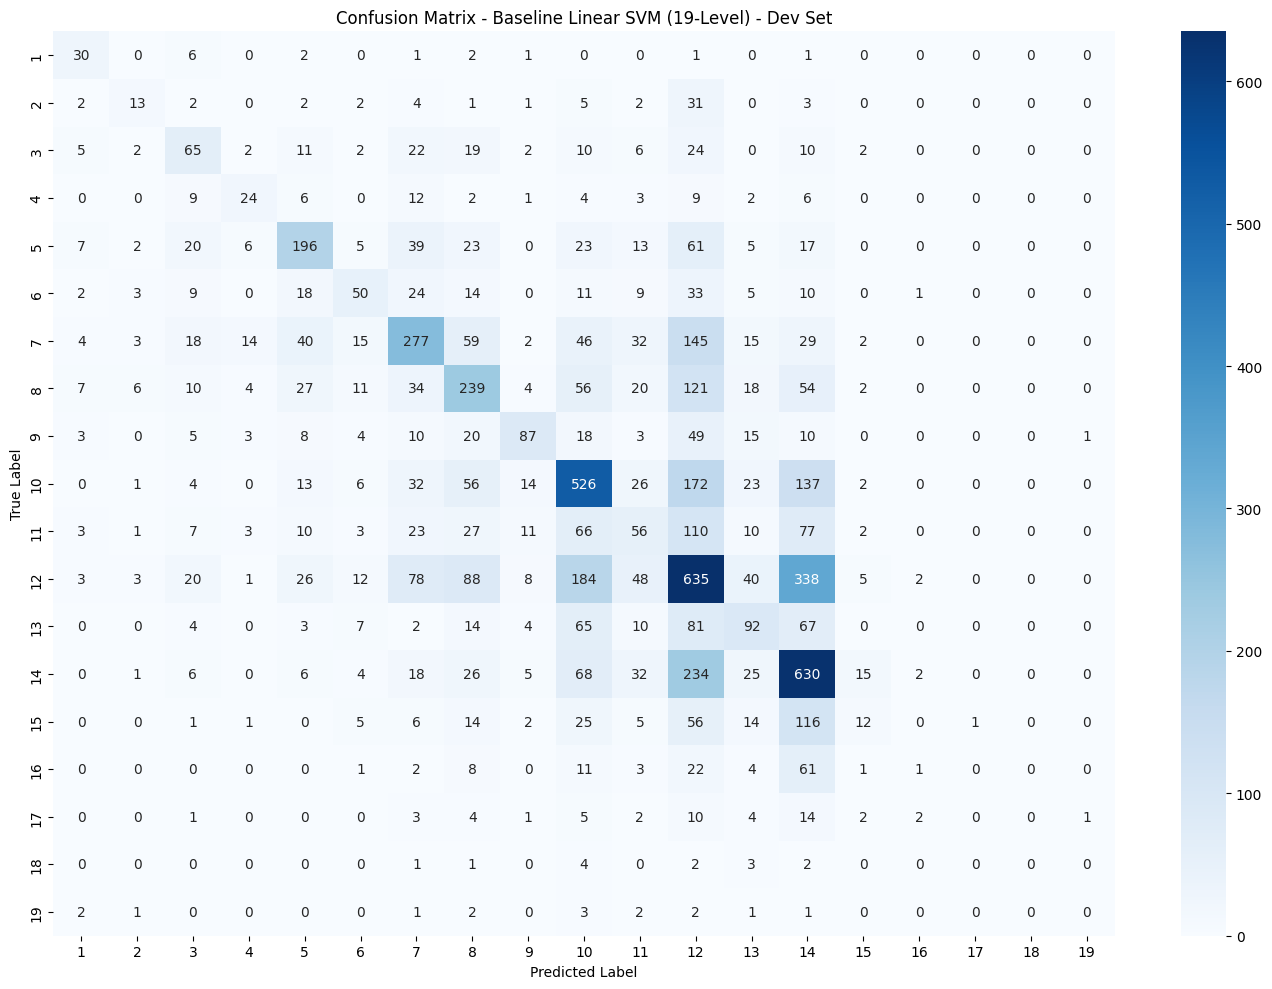

In [14]:
# Import Linear Support Vector Classifier
from sklearn.svm import LinearSVC

# Create the baseline Linear SVM model using default hyperparameters
svm_baseline_19 = LinearSVC(
    random_state=42
)

print(svm_baseline_19.get_params())

# Train the baseline model on the training set
svm_baseline_19.fit(
    svm_X_train_tfidf,
    svm_y_train_19
)

# Generate predictions on the development set
svm_baseline_19_dev_pred = svm_baseline_19.predict(
    svm_X_dev_tfidf
)

# Evaluate the baseline model on the development set
evaluate_svm_model(
    svm_y_dev_19,
    svm_baseline_19_dev_pred,
    "Baseline SVM (19-Level) - Dev Set"
)

# Plot the confusion matrix
plot_confusion_matrix(
    svm_y_dev_19,
    svm_baseline_19_dev_pred,
    labels=list(range(1, 20)),
    title="Confusion Matrix - Baseline Linear SVM (19-Level) - Dev Set"
)

### 4.2 SVM Baseline Findings (19-Level)

The baseline SVM achieved an Accuracy of **0.4012** and a Quadratic Weighted Kappa (QWK) of **0.5487** on the development set. Adjacent Accuracy was **0.5157**, with a Macro F1-score of **0.2889**.

The model struggled to classify higher readability levels, particularly Levels 15–19, with very low recall and no correctly classified samples from Levels 17–19. These results establish the baseline performance for comparison with the tuned SVM models.

### 4.3 SVM Hyperparameter Tuning Using GridSearchCV (19-Level)

GridSearchCV was used to identify the best combination of hyperparameters for the Linear SVM model. The search focused on `C` and `loss`, while the remaining parameters were kept at their default values.

**Hyperparameters and Search Space**

- **C (Regularization Parameter):** Controls the trade-off between maximizing the classification margin and penalizing classification errors. The values `[0.01, 0.1, 1, 10, 100]` cover multiple orders of magnitude, allowing the model to be tested under different regularization strengths.

- **Loss Function:** Defines the loss formulation used during model training. Both `hinge` and `squared_hinge` were tested because they are supported by `LinearSVC` and allow comparison between standard hinge loss and its squared version.

A predefined split preserves the original training and development sets. QWK is used to select the best hyperparameter combination.

In [15]:
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.svm import LinearSVC
from sklearn.metrics import make_scorer, cohen_kappa_score
from scipy.sparse import vstack
import numpy as np

# Define the hyperparameter search space
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "loss": ["hinge", "squared_hinge"]
}

# Combine training and development data
X_train_dev = vstack([
    svm_X_train_tfidf,
    svm_X_dev_tfidf
])

y_train_dev = np.concatenate([
    svm_y_train_19,
    svm_y_dev_19
])

# Use training data for fitting and development data for validation
test_fold = np.concatenate([
    np.full(len(svm_y_train_19), -1),
    np.zeros(len(svm_y_dev_19))
])

predefined_split = PredefinedSplit(test_fold=test_fold)

# Define Quadratic Weighted Kappa as the scoring metric
qwk_scorer = make_scorer(
    cohen_kappa_score,
    weights="quadratic"
)

# Configure GridSearchCV
svm_grid_19 = GridSearchCV(
    estimator=LinearSVC(random_state=42, max_iter=5000),
    param_grid=param_grid,
    scoring=qwk_scorer,
    cv=predefined_split,
    n_jobs=-1,
    verbose=2
)

# Run hyperparameter tuning
svm_grid_19.fit(X_train_dev, y_train_dev)

print("Best Parameters:", svm_grid_19.best_params_)
print(f"Best Development QWK: {svm_grid_19.best_score_:.4f}")

Fitting 1 folds for each of 10 candidates, totalling 10 fits
Best Parameters: {'C': 1, 'loss': 'squared_hinge'}
Best Development QWK: 0.5487


### 4.4 Tuned SVM — Balanced (19-Level)

Tuned SVM (19-Level) - Balanced - Dev Set
Accuracy:                      0.3807
Adjacent Accuracy (±1):        0.5115
Quadratic Weighted Kappa:      0.5421
Macro F1-score:                0.2656
Weighted Precision:            0.3815
Weighted Recall:               0.3807
Mean Absolute Error (MAE):     2.1740
Root Mean Squared Error:       3.3773
R² Score:                      -0.0034

Classification Report:

              precision    recall  f1-score   support

           1       0.21      0.68      0.32        44
           2       0.16      0.22      0.19        68
           3       0.25      0.41      0.31       182
           4       0.17      0.33      0.23        78
           5       0.46      0.48      0.47       417
           6       0.28      0.34      0.31       189
           7       0.44      0.41      0.42       701
           8       0.36      0.41      0.38       613
           9       0.46      0.40      0.43       236
          10       0.51      0.49      0.50      

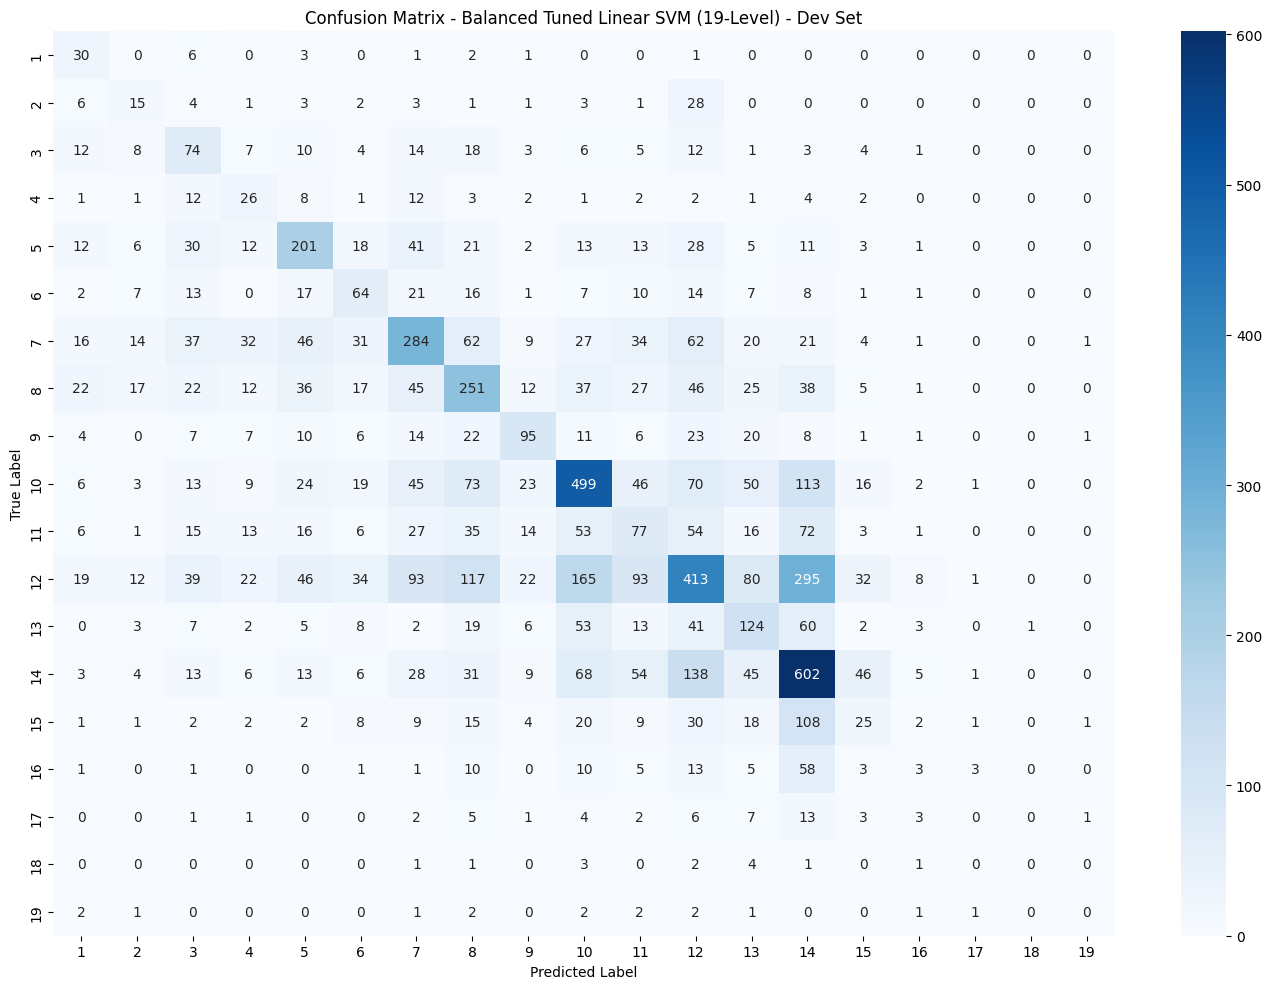

In [16]:
svm_tuned_19_balanced = LinearSVC(
    C=svm_grid_19.best_params_["C"],
    loss=svm_grid_19.best_params_["loss"],
    class_weight="balanced",
    random_state=42,
    max_iter=5000
)

# Train the tuned model on the training set
svm_tuned_19_balanced.fit(
    svm_X_train_tfidf,
    svm_y_train_19
)

# Generate predictions on the development set
svm_tuned_19_balanced_dev_pred = svm_tuned_19_balanced.predict(
    svm_X_dev_tfidf
)

# Evaluate the model on the development set
evaluate_svm_model(
    svm_y_dev_19,
    svm_tuned_19_balanced_dev_pred,
    "Tuned SVM (19-Level) - Balanced - Dev Set"
)

# Plot the confusion matrix
plot_confusion_matrix(
    svm_y_dev_19,
    svm_tuned_19_balanced_dev_pred,
    labels=list(range(1, 20)),
    title="Confusion Matrix - Balanced Tuned Linear SVM (19-Level) - Dev Set"
)

### 4.5 Tuned SVM — No Class Weighting (19-Level)

Tuned SVM (19-Level) - No Class Weighting - Dev Set
Accuracy:                      0.4012
Adjacent Accuracy (±1):        0.5157
Quadratic Weighted Kappa:      0.5487
Macro F1-score:                0.2889
Weighted Precision:            0.3904
Weighted Recall:               0.4012
Mean Absolute Error (MAE):     1.9958
Root Mean Squared Error:       3.1123
R² Score:                      0.1479

Classification Report:

              precision    recall  f1-score   support

           1       0.44      0.68      0.54        44
           2       0.36      0.19      0.25        68
           3       0.35      0.36      0.35       182
           4       0.41      0.31      0.35        78
           5       0.53      0.47      0.50       417
           6       0.39      0.26      0.32       189
           7       0.47      0.40      0.43       701
           8       0.39      0.39      0.39       613
           9       0.61      0.37      0.46       236
          10       0.47      0.52      0

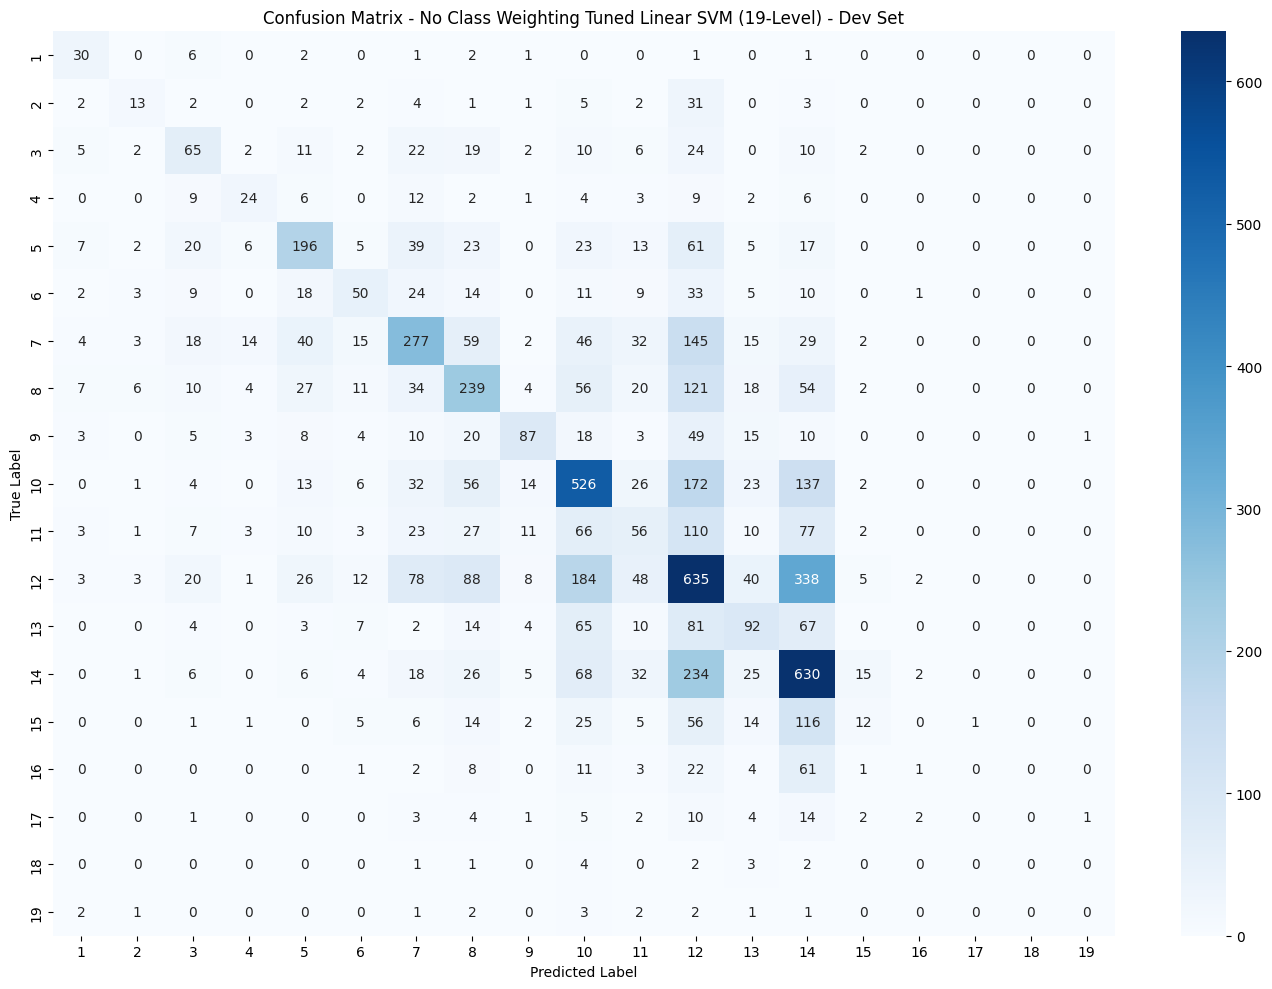

In [25]:
svm_tuned_19_none = LinearSVC(
    C=svm_grid_19.best_params_["C"],
    loss=svm_grid_19.best_params_["loss"],
    class_weight=None,
    random_state=42,
    max_iter=5000
)

# Train the tuned model on the training set
svm_tuned_19_none.fit(
    svm_X_train_tfidf,
    svm_y_train_19
)

# Generate predictions on the development set
svm_tuned_19_none_dev_pred = svm_tuned_19_none.predict(
    svm_X_dev_tfidf
)

# Evaluate the model on the development set
evaluate_svm_model(
    svm_y_dev_19,
    svm_tuned_19_none_dev_pred,
    "Tuned SVM (19-Level) - No Class Weighting - Dev Set"
)

# Plot the confusion matrix
plot_confusion_matrix(
    svm_y_dev_19,
    svm_tuned_19_none_dev_pred,
    labels=list(range(1, 20)),
    title="Confusion Matrix - No Class Weighting Tuned Linear SVM (19-Level) - Dev Set"
)

### 4.6 Tuned SVM Findings (19-Level)

GridSearchCV selected `C = 1` and `loss = squared_hinge` as the best hyperparameter configuration, achieving a development QWK of **0.5487**.

On the development set, the tuned SVM with `class_weight="balanced"` achieved an Accuracy of **0.3807** and a QWK of **0.5421**. In comparison, the unweighted model achieved an Accuracy of **0.4012** and a QWK of **0.5487**.

The unweighted model also achieved a higher Macro F1-score (**0.2889** versus **0.2656**) and lower MAE (**1.9958** versus **2.1740**).

Therefore, class weighting did not improve performance. The unweighted SVM was selected as the preferred configuration for subsequent experiments based on its higher development QWK and better overall metrics.

## **5. SVM (5-Level)**

### 5.1 SVM Baseline (5-Level)

A baseline Linear SVM is trained for the 5-level Arabic readability classification task using the same TF-IDF features and default hyperparameters. The model is evaluated on the development set to establish a baseline for subsequent hyperparameter tuning.

{'C': 1.0, 'class_weight': None, 'dual': 'auto', 'fit_intercept': True, 'intercept_scaling': 1, 'loss': 'squared_hinge', 'max_iter': 1000, 'multi_class': 'ovr', 'penalty': 'l2', 'random_state': 42, 'tol': 0.0001, 'verbose': 0}
Baseline SVM (5-Level) - Dev Set
Accuracy:                      0.5438
Adjacent Accuracy (±1):        0.8575
Quadratic Weighted Kappa:      0.5640
Macro F1-score:                0.4517
Weighted Precision:            0.5521
Weighted Recall:               0.5438
Mean Absolute Error (MAE):     0.6254
Root Mean Squared Error:       1.0099
R² Score:                      0.1699

Classification Report:

              precision    recall  f1-score   support

           1       0.66      0.65      0.66      1679
           2       0.56      0.59      0.57      2270
           3       0.45      0.43      0.44      1840
           4       0.50      0.56      0.53      1330
           5       0.86      0.03      0.06       191

    accuracy                           0.54    

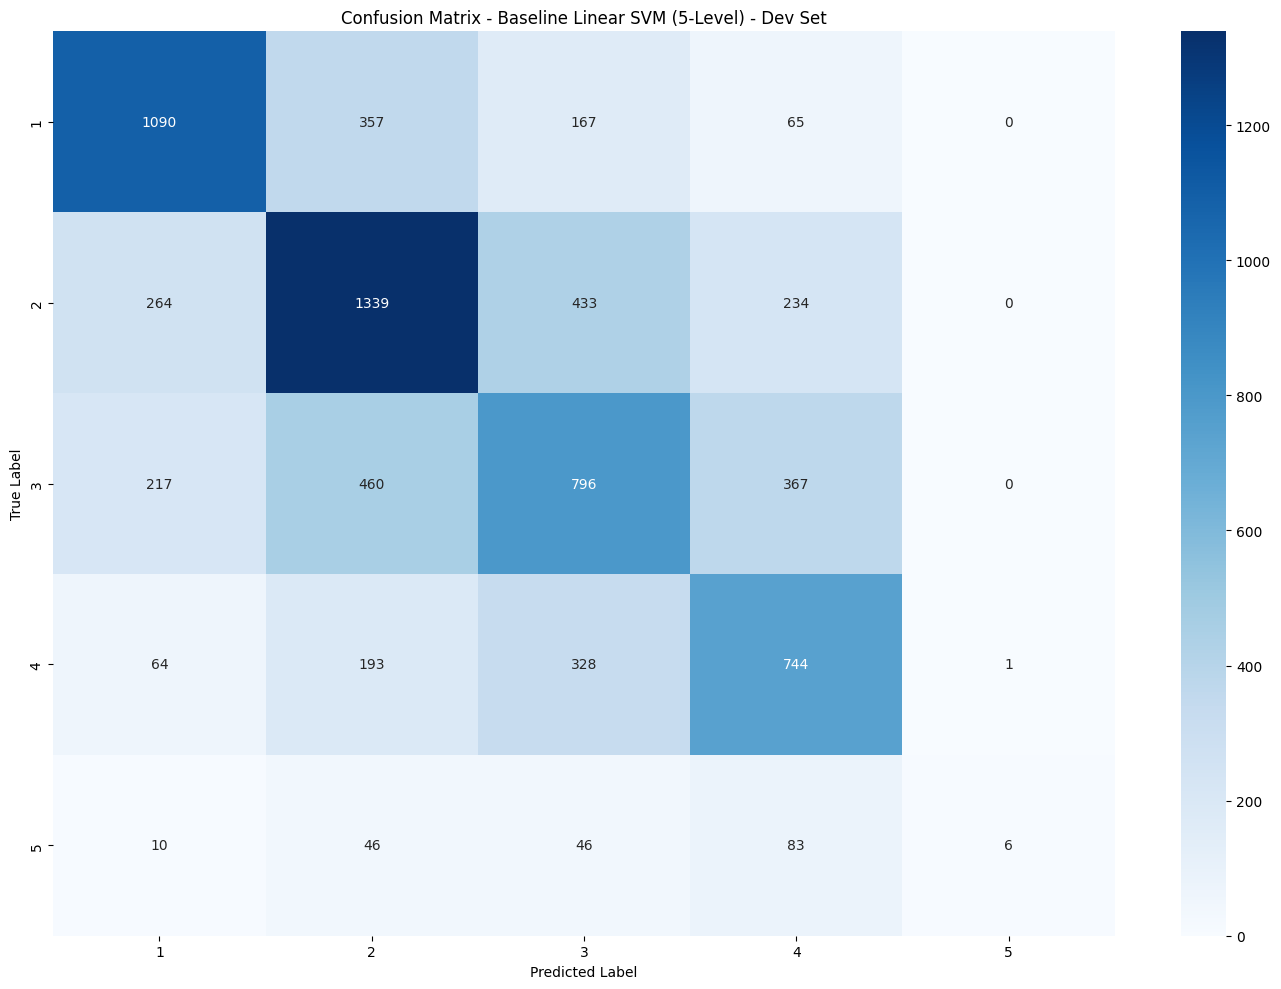

In [17]:
# Define target labels for the 5-level classification task
svm_y_train_5 = train_original["Readability_Level_5"]
svm_y_dev_5 = dev_original["Readability_Level_5"]
svm_y_test_5 = test_original["Readability_Level_5"]

# Create the baseline Linear SVM model using default hyperparameters
svm_baseline_5 = LinearSVC(
    random_state=42
)

print(svm_baseline_5.get_params())

# Train the baseline model on the training set
svm_baseline_5.fit(
    svm_X_train_tfidf,
    svm_y_train_5
)

# Generate predictions on the development set
svm_baseline_5_dev_pred = svm_baseline_5.predict(
    svm_X_dev_tfidf
)

# Evaluate the baseline model on the development set
evaluate_svm_model(
    svm_y_dev_5,
    svm_baseline_5_dev_pred,
    "Baseline SVM (5-Level) - Dev Set"
)

# Plot the confusion matrix
plot_confusion_matrix(
    svm_y_dev_5,
    svm_baseline_5_dev_pred,
    labels=sorted(svm_y_train_5.unique()),
    title="Confusion Matrix - Baseline Linear SVM (5-Level) - Dev Set"
)

### 5.2 SVM Baseline Findings (5-Level)

The baseline SVM achieved an Accuracy of **0.5438** and a Quadratic Weighted Kappa (QWK) of **0.5640** on the development set. Adjacent Accuracy was **0.8575**, while the Macro F1-score was **0.4517**.

The model struggled to identify Level 5, achieving a recall of only **0.03**. These results establish the baseline performance for comparison with the tuned SVM models.

### 5.3 SVM Hyperparameter Tuning Using GridSearchCV (5-Level)

GridSearchCV was used to identify the best combination of hyperparameters for the Linear SVM model. The search focused on `C` and `loss`, while the remaining parameters were kept at their default values.

**Hyperparameters and Search Space**

- **C (Regularization Parameter):** Controls the trade-off between maximizing the classification margin and penalizing classification errors. The values `[0.01, 0.1, 1, 10, 100]` cover multiple orders of magnitude, allowing the model to be tested under different regularization strengths.

- **Loss Function:** Defines the loss formulation used during model training. Both `hinge` and `squared_hinge` were tested because they are supported by `LinearSVC` and allow comparison between standard hinge loss and its squared version.

A predefined split preserves the original training and development sets. QWK is used to select the best hyperparameter combination.

In [18]:
# Hyperparameter search space
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "loss": ["hinge", "squared_hinge"]
}

# Combine training and development features
X_train_dev = vstack([
    svm_X_train_tfidf,
    svm_X_dev_tfidf
])

# Combine labels for the 5-level task
y_train_dev_5 = np.concatenate([
    svm_y_train_5,
    svm_y_dev_5
])

# Preserve the original training-development split
test_fold_5 = np.concatenate([
    np.full(len(svm_y_train_5), -1),
    np.zeros(len(svm_y_dev_5))
])

predefined_split_5 = PredefinedSplit(test_fold=test_fold_5)

# Define Quadratic Weighted Kappa as the scoring metric
qwk_scorer = make_scorer(
    cohen_kappa_score,
    weights="quadratic"
)

# Grid Search using QWK
svm_grid_5 = GridSearchCV(
    estimator=LinearSVC(random_state=42, max_iter=5000),
    param_grid=param_grid,
    scoring=qwk_scorer,
    cv=predefined_split_5,
    n_jobs=-1,
    verbose=2
)

# Run hyperparameter tuning
svm_grid_5.fit(X_train_dev, y_train_dev_5)

print("Best Parameters:", svm_grid_5.best_params_)
print(f"Best Development QWK: {svm_grid_5.best_score_:.4f}")

Fitting 1 folds for each of 10 candidates, totalling 10 fits
Best Parameters: {'C': 1, 'loss': 'squared_hinge'}
Best Development QWK: 0.5640


### 5.4 Tuned SVM — Balanced (5-Level)

Tuned SVM (5-Level) - Balanced - Dev Set
Accuracy:                      0.5438
Adjacent Accuracy (±1):        0.8516
Quadratic Weighted Kappa:      0.5699
Macro F1-score:                0.4634
Weighted Precision:            0.5434
Weighted Recall:               0.5438
Mean Absolute Error (MAE):     0.6330
Root Mean Squared Error:       1.0228
R² Score:                      0.1486

Classification Report:

              precision    recall  f1-score   support

           1       0.65      0.68      0.66      1679
           2       0.58      0.55      0.57      2270
           3       0.45      0.42      0.44      1840
           4       0.48      0.59      0.53      1330
           5       0.50      0.07      0.12       191

    accuracy                           0.54      7310
   macro avg       0.53      0.46      0.46      7310
weighted avg       0.54      0.54      0.54      7310



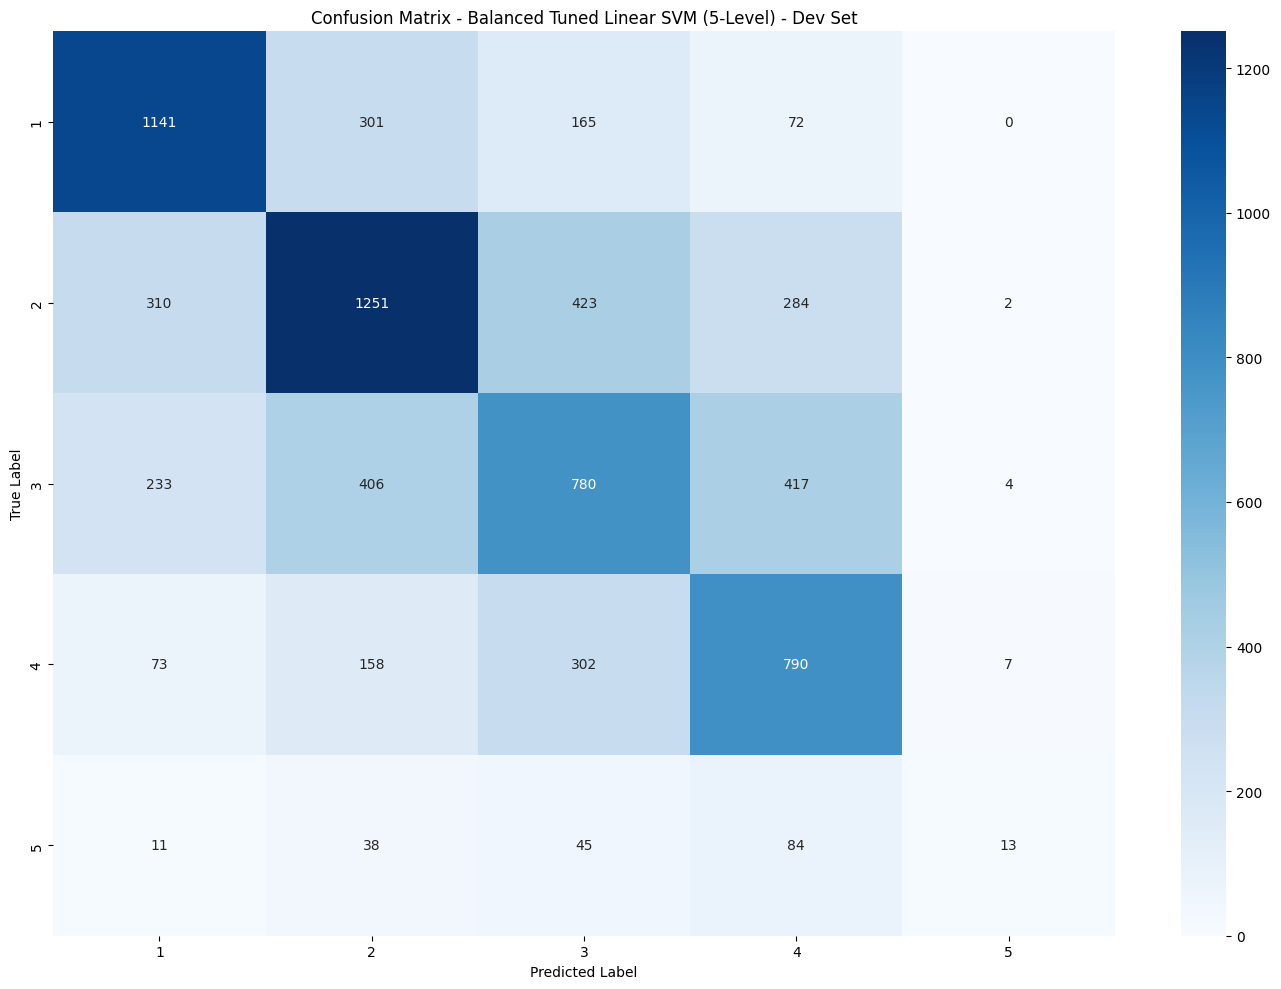

In [19]:
svm_tuned_5_balanced = LinearSVC(
    C=svm_grid_5.best_params_["C"],
    loss=svm_grid_5.best_params_["loss"],
    class_weight="balanced",
    random_state=42,
    max_iter=5000
)

# Train the tuned model on the training set
svm_tuned_5_balanced.fit(
    svm_X_train_tfidf,
    svm_y_train_5
)

# Generate predictions on the development set
svm_tuned_5_balanced_dev_pred = svm_tuned_5_balanced.predict(
    svm_X_dev_tfidf
)

# Evaluate the model on the development set
evaluate_svm_model(
    svm_y_dev_5,
    svm_tuned_5_balanced_dev_pred,
    "Tuned SVM (5-Level) - Balanced - Dev Set"
)

# Plot the confusion matrix
plot_confusion_matrix(
    svm_y_dev_5,
    svm_tuned_5_balanced_dev_pred,
    labels=sorted(svm_y_train_5.unique()),
    title="Confusion Matrix - Balanced Tuned Linear SVM (5-Level) - Dev Set"
)

### 5.5 Tuned SVM — No Class Weighting (5-Level)

Tuned SVM (5-Level) - No Class Weighting - Dev Set
Accuracy:                      0.5438
Adjacent Accuracy (±1):        0.8575
Quadratic Weighted Kappa:      0.5640
Macro F1-score:                0.4517
Weighted Precision:            0.5521
Weighted Recall:               0.5438
Mean Absolute Error (MAE):     0.6254
Root Mean Squared Error:       1.0099
R² Score:                      0.1699

Classification Report:

              precision    recall  f1-score   support

           1       0.66      0.65      0.66      1679
           2       0.56      0.59      0.57      2270
           3       0.45      0.43      0.44      1840
           4       0.50      0.56      0.53      1330
           5       0.86      0.03      0.06       191

    accuracy                           0.54      7310
   macro avg       0.61      0.45      0.45      7310
weighted avg       0.55      0.54      0.54      7310



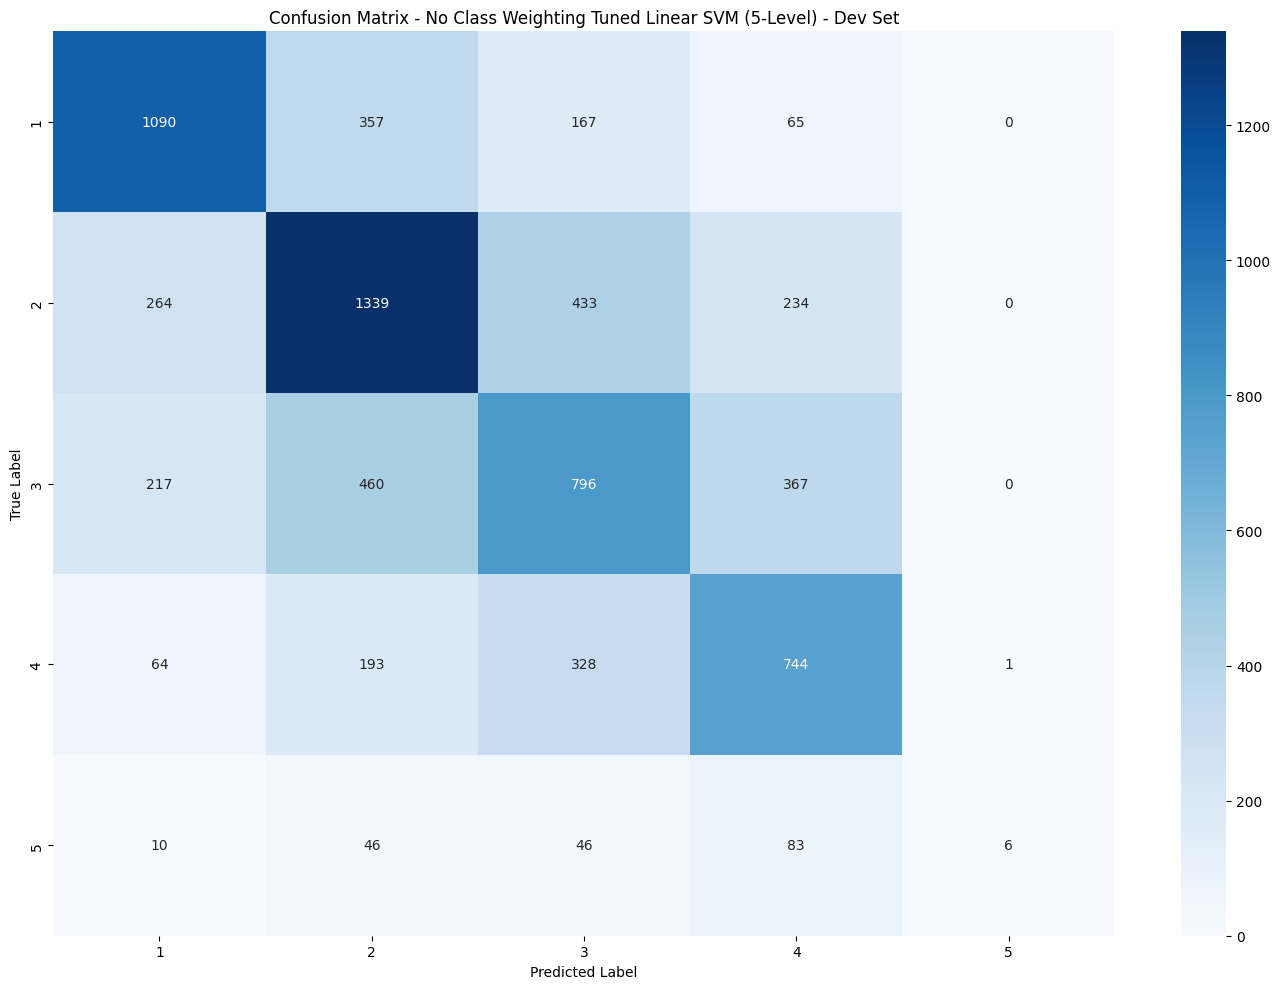

In [20]:
svm_tuned_5_none = LinearSVC(
    C=svm_grid_5.best_params_["C"],
    loss=svm_grid_5.best_params_["loss"],
    class_weight=None,
    random_state=42,
    max_iter=5000
)

# Train the tuned model on the training set
svm_tuned_5_none.fit(
    svm_X_train_tfidf,
    svm_y_train_5
)

# Generate predictions on the development set
svm_tuned_5_none_dev_pred = svm_tuned_5_none.predict(
    svm_X_dev_tfidf
)

# Evaluate the model on the development set
evaluate_svm_model(
    svm_y_dev_5,
    svm_tuned_5_none_dev_pred,
    "Tuned SVM (5-Level) - No Class Weighting - Dev Set"
)

# Plot the confusion matrix
plot_confusion_matrix(
    svm_y_dev_5,
    svm_tuned_5_none_dev_pred,
    labels=sorted(svm_y_train_5.unique()),
    title="Confusion Matrix - No Class Weighting Tuned Linear SVM (5-Level) - Dev Set"
)

### 5.6 SVM Tuned Findings (5-Level)

GridSearchCV selected `C = 1` and `loss = squared_hinge` based on the highest development QWK of **0.5640**.

On the development set, the balanced SVM achieved a QWK of **0.5699** and a Macro F1-score of **0.4634**, compared with **0.5640** and **0.4517**, respectively, for the unweighted model. Both configurations achieved the same Accuracy of **0.5438**.

Class weighting slightly improved QWK and Macro F1-score, while the unweighted model achieved higher Adjacent Accuracy (**0.8575** versus **0.8516**). However, Level 5 recall remained low in both configurations, reaching **0.07** with class weighting and **0.03** without it.

Overall, the balanced model performed better in terms of QWK and Macro F1-score, making it the preferred configuration based on the development set.

## **6. SVM (4-Level)**

### 6.1 SVM Baseline (4-Level)

A baseline Linear SVM is trained for the 4-level Arabic readability classification task using the existing TF-IDF features and default hyperparameters. The model is evaluated on the development set to establish a baseline for subsequent hyperparameter tuning.

{'C': 1.0, 'class_weight': None, 'dual': 'auto', 'fit_intercept': True, 'intercept_scaling': 1, 'loss': 'squared_hinge', 'max_iter': 1000, 'multi_class': 'ovr', 'penalty': 'l2', 'random_state': 42, 'tol': 0.0001, 'verbose': 0}
Baseline SVM (4-Level) - Dev Set
Accuracy:                      0.5598
Adjacent Accuracy (±1):        0.8632
Quadratic Weighted Kappa:      0.5814
Macro F1-score:                0.5603
Weighted Precision:            0.5584
Weighted Recall:               0.5598
Mean Absolute Error (MAE):     0.5971
Root Mean Squared Error:       0.9753
R² Score:                      0.1520

Classification Report:

              precision    recall  f1-score   support

           1       0.66      0.64      0.65      1679
           2       0.57      0.58      0.57      2270
           3       0.46      0.42      0.44      1840
           4       0.55      0.60      0.57      1521

    accuracy                           0.56      7310
   macro avg       0.56      0.56      0.56    

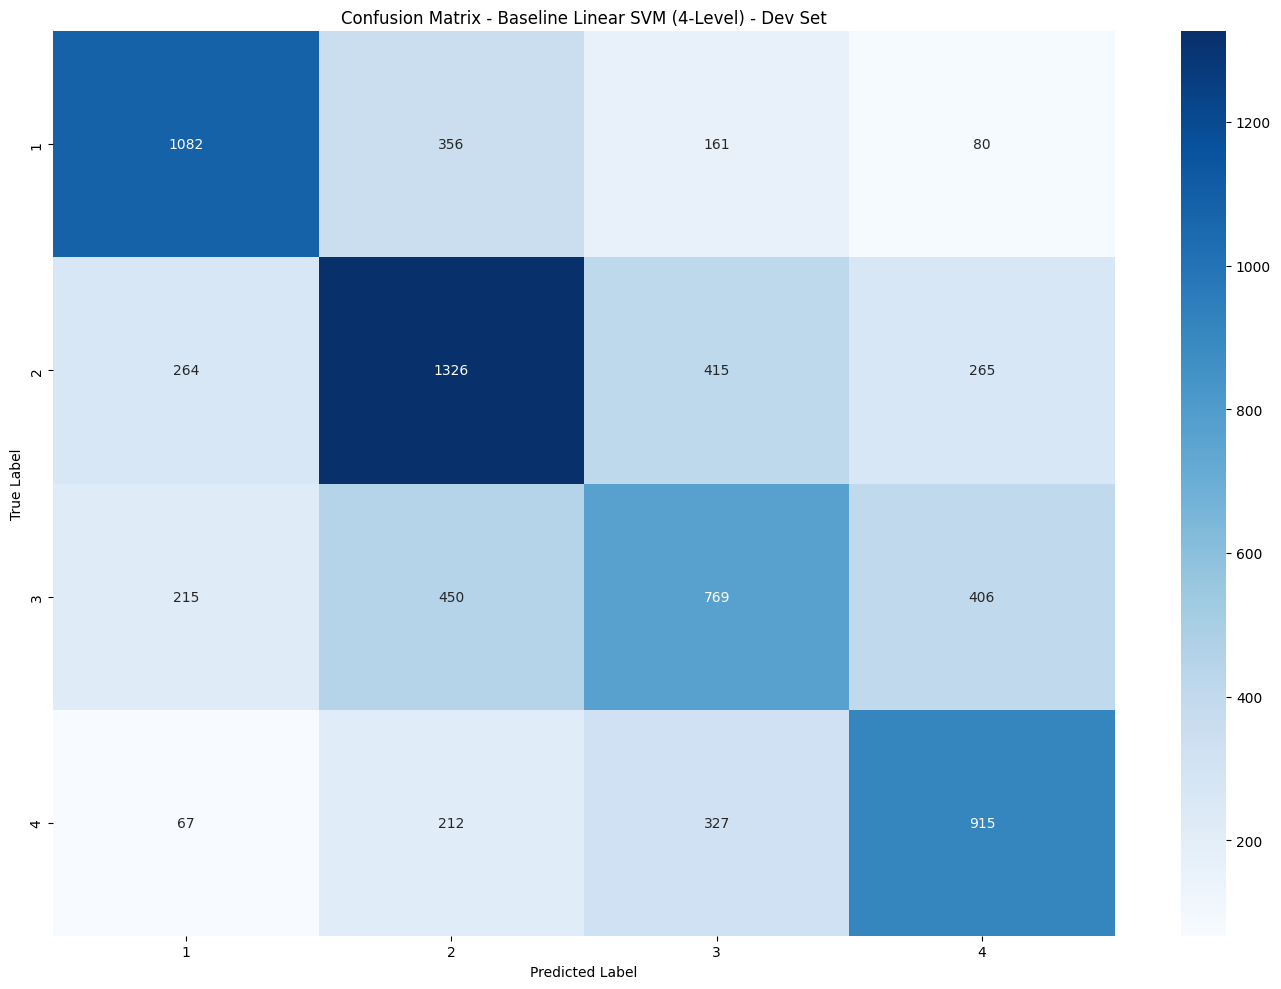

In [21]:
# Define target labels for the 4-level classification task
svm_y_train_4 = train_4level["Readability_Level_4"]
svm_y_dev_4 = dev_4level["Readability_Level_4"]
svm_y_test_4 = test_4level["Readability_Level_4"]

# Create the baseline Linear SVM model using default hyperparameters
svm_baseline_4 = LinearSVC(
    random_state=42
)

print(svm_baseline_4.get_params())

# Train the baseline model on the training set
svm_baseline_4.fit(
    svm_X_train_tfidf,
    svm_y_train_4
)

# Generate predictions on the development set
svm_baseline_4_dev_pred = svm_baseline_4.predict(
    svm_X_dev_tfidf
)

# Evaluate the baseline model on the development set
evaluate_svm_model(
    svm_y_dev_4,
    svm_baseline_4_dev_pred,
    "Baseline SVM (4-Level) - Dev Set"
)

# Plot the confusion matrix
plot_confusion_matrix(
    svm_y_dev_4,
    svm_baseline_4_dev_pred,
    labels=sorted(svm_y_train_4.unique()),
    title="Confusion Matrix - Baseline Linear SVM (4-Level) - Dev Set"
)

### 6.2 SVM Baseline Findings (4-Level)

The baseline SVM achieved an Accuracy of **0.5598** and a Quadratic Weighted Kappa (QWK) of **0.5814** on the development set. Adjacent Accuracy was **0.8632**, and the Macro F1-score was **0.5603**.

Performance varied across the four classes, with F1-scores ranging from **0.44** for Level 3 to **0.65** for Level 1. Level 4 achieved an F1-score of **0.57**, while Level 2 achieved **0.57**. These results establish the baseline performance for comparison with the tuned SVM models.

### 6.3 SVM Hyperparameter Tuning Using GridSearchCV (4-Level)

GridSearchCV was used to identify the best combination of hyperparameters for the Linear SVM model. The search focused on `C` and `loss`, while the remaining parameters were kept at their default values.

**Hyperparameters and Search Space**

- **C (Regularization Parameter):** Controls the trade-off between maximizing the classification margin and penalizing classification errors. The values `[0.01, 0.1, 1, 10, 100]` cover multiple orders of magnitude, allowing the model to be tested under different regularization strengths.

- **Loss Function:** Defines the loss formulation used during model training. Both `hinge` and `squared_hinge` were tested because they are supported by `LinearSVC` and allow comparison between standard hinge loss and its squared version.

A predefined split preserves the original training and development sets. QWK is used to select the best hyperparameter combination.

In [22]:
# Define the hyperparameter search space
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "loss": ["hinge", "squared_hinge"]
}

# Combine training and development features
X_train_dev_4 = vstack([
    svm_X_train_tfidf,
    svm_X_dev_tfidf
])

# Combine training and development labels for the 4-level task
y_train_dev_4 = np.concatenate([
    svm_y_train_4,
    svm_y_dev_4
])

# Preserve the original training-development split
test_fold_4 = np.concatenate([
    np.full(len(svm_y_train_4), -1),
    np.zeros(len(svm_y_dev_4))
])

predefined_split_4 = PredefinedSplit(
    test_fold=test_fold_4
)

# Define Quadratic Weighted Kappa as the scoring metric
qwk_scorer = make_scorer(
    cohen_kappa_score,
    weights="quadratic"
)

# Configure GridSearchCV
svm_grid_4 = GridSearchCV(
    estimator=LinearSVC(
        random_state=42,
        max_iter=5000
    ),
    param_grid=param_grid,
    scoring=qwk_scorer,
    cv=predefined_split_4,
    n_jobs=-1,
    verbose=2
)

# Run hyperparameter tuning
svm_grid_4.fit(
    X_train_dev_4,
    y_train_dev_4
)

# Display the best configuration and its development QWK
print("Best Parameters:", svm_grid_4.best_params_)
print(f"Best Development QWK: {svm_grid_4.best_score_:.4f}")

Fitting 1 folds for each of 10 candidates, totalling 10 fits
Best Parameters: {'C': 1, 'loss': 'squared_hinge'}
Best Development QWK: 0.5814


### 6.4 Tuned SVM — Balanced (4-Level)

Tuned SVM (4-Level) - Balanced - Dev Set
Accuracy:                      0.5617
Adjacent Accuracy (±1):        0.8610
Quadratic Weighted Kappa:      0.5868
Macro F1-score:                0.5620
Weighted Precision:            0.5598
Weighted Recall:               0.5617
Mean Absolute Error (MAE):     0.5985
Root Mean Squared Error:       0.9805
R² Score:                      0.1430

Classification Report:

              precision    recall  f1-score   support

           1       0.65      0.67      0.66      1679
           2       0.59      0.56      0.57      2270
           3       0.46      0.42      0.44      1840
           4       0.54      0.62      0.58      1521

    accuracy                           0.56      7310
   macro avg       0.56      0.57      0.56      7310
weighted avg       0.56      0.56      0.56      7310



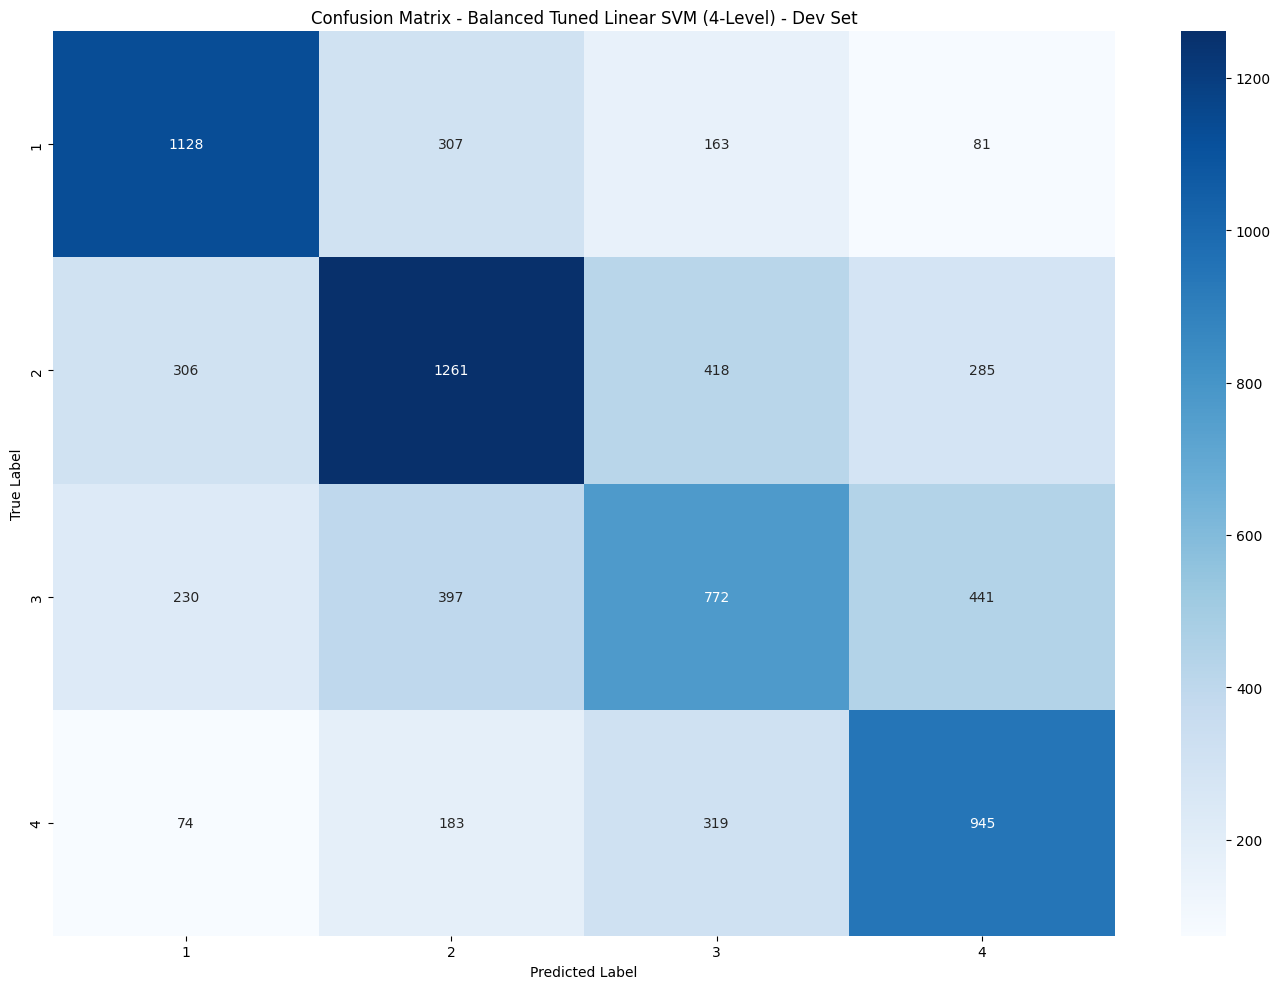

In [23]:
# Create the tuned 4-level SVM with balanced class weights
svm_tuned_4_balanced = LinearSVC(
    C=svm_grid_4.best_params_["C"],
    loss=svm_grid_4.best_params_["loss"],
    class_weight="balanced",
    random_state=42,
    max_iter=5000
)

# Train the model on the training set
svm_tuned_4_balanced.fit(
    svm_X_train_tfidf,
    svm_y_train_4
)

# Generate predictions on the development set
svm_tuned_4_balanced_dev_pred = svm_tuned_4_balanced.predict(
    svm_X_dev_tfidf
)

# Evaluate the model on the development set
evaluate_svm_model(
    svm_y_dev_4,
    svm_tuned_4_balanced_dev_pred,
    "Tuned SVM (4-Level) - Balanced - Dev Set"
)

# Plot the confusion matrix
plot_confusion_matrix(
    svm_y_dev_4,
    svm_tuned_4_balanced_dev_pred,
    labels=sorted(svm_y_train_4.unique()),
    title="Confusion Matrix - Balanced Tuned Linear SVM (4-Level) - Dev Set"
)

### 6.5 Tuned SVM — No Class Weighting (4-Level)

Tuned SVM (4-Level) - No Class Weighting - Dev Set
Accuracy:                      0.5598
Adjacent Accuracy (±1):        0.8632
Quadratic Weighted Kappa:      0.5814
Macro F1-score:                0.5603
Weighted Precision:            0.5584
Weighted Recall:               0.5598
Mean Absolute Error (MAE):     0.5971
Root Mean Squared Error:       0.9753
R² Score:                      0.1520

Classification Report:

              precision    recall  f1-score   support

           1       0.66      0.64      0.65      1679
           2       0.57      0.58      0.57      2270
           3       0.46      0.42      0.44      1840
           4       0.55      0.60      0.57      1521

    accuracy                           0.56      7310
   macro avg       0.56      0.56      0.56      7310
weighted avg       0.56      0.56      0.56      7310



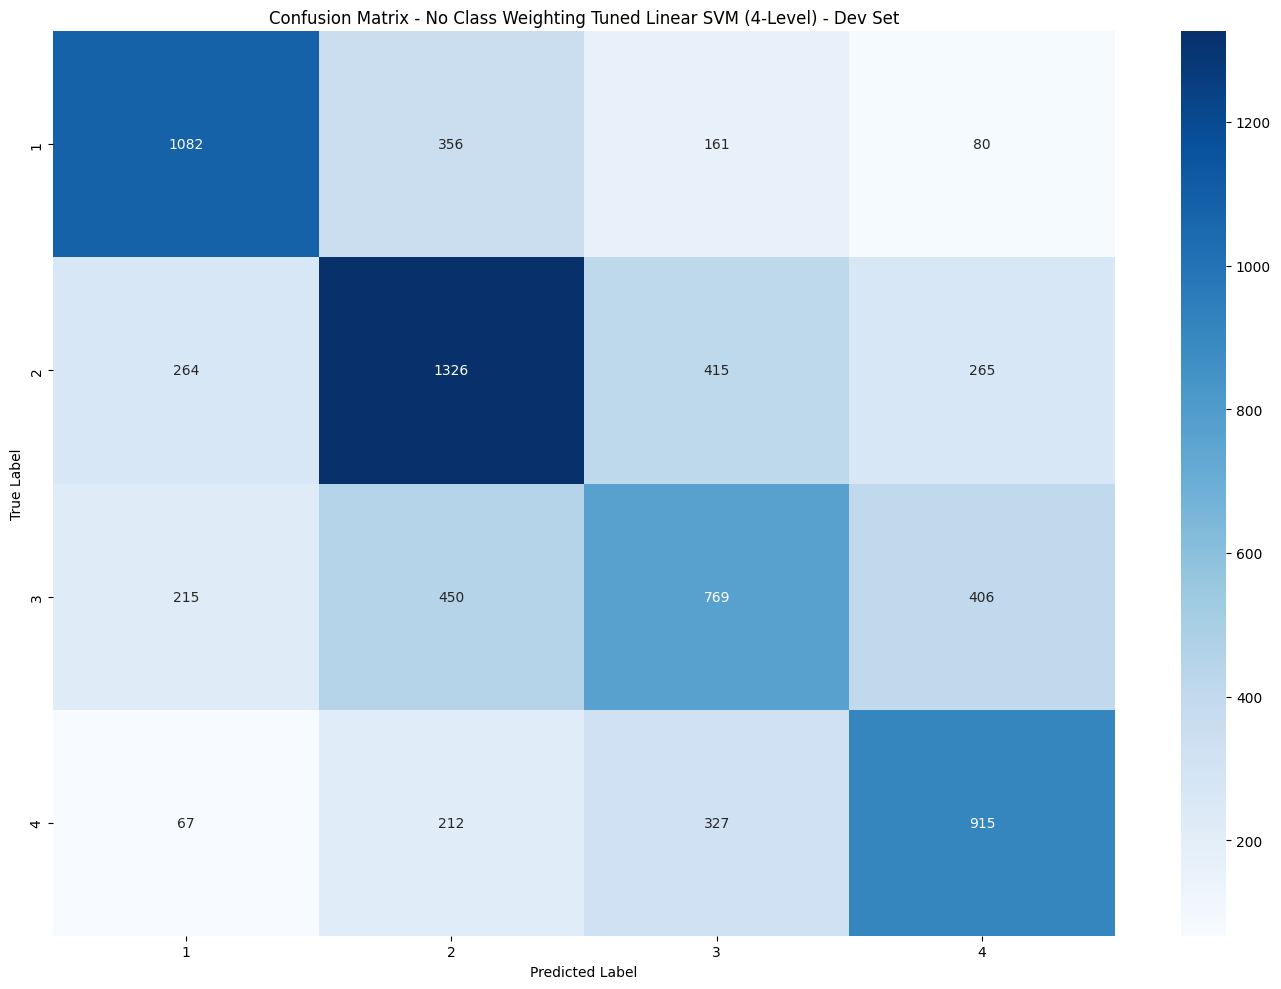

In [24]:
# Create the tuned 4-level SVM without class weighting
svm_tuned_4_none = LinearSVC(
    C=svm_grid_4.best_params_["C"],
    loss=svm_grid_4.best_params_["loss"],
    class_weight=None,
    random_state=42,
    max_iter=5000
)

# Train the model on the training set
svm_tuned_4_none.fit(
    svm_X_train_tfidf,
    svm_y_train_4
)

# Generate predictions on the development set
svm_tuned_4_none_dev_pred = svm_tuned_4_none.predict(
    svm_X_dev_tfidf
)

# Evaluate the model on the development set
evaluate_svm_model(
    svm_y_dev_4,
    svm_tuned_4_none_dev_pred,
    "Tuned SVM (4-Level) - No Class Weighting - Dev Set"
)

# Plot the confusion matrix
plot_confusion_matrix(
    svm_y_dev_4,
    svm_tuned_4_none_dev_pred,
    labels=sorted(svm_y_train_4.unique()),
    title="Confusion Matrix - No Class Weighting Tuned Linear SVM (4-Level) - Dev Set"
)

### 6.6 SVM Tuned Findings (4-Level)

GridSearchCV selected `C = 1` and `loss = squared_hinge` based on the highest development QWK of **0.5814**.

On the development set, the balanced SVM achieved an Accuracy of **0.5617**, a QWK of **0.5868**, and a Macro F1-score of **0.5620**. Compared with the unweighted model, which achieved an Accuracy of **0.5598**, a QWK of **0.5814**, and a Macro F1-score of **0.5603**, class weighting slightly improved overall performance.

However, the unweighted model achieved a higher Adjacent Accuracy (**0.8632** versus **0.8610**) and lower MAE (**0.5971** versus **0.5985**).

Overall, the balanced SVM was selected as the preferred configuration based on its higher development QWK and Macro F1-score.

## **7. Final SVM Experimental Comparison**

### 7.1 Overall Performance Comparison

The baseline and tuned Linear SVM models were evaluated on the development set across the 19-level, 5-level, and 4-level readability classification tasks. Quadratic Weighted Kappa (QWK) was used as the scoring metric for hyperparameter selection.

<br>

| Classification Level | Model | Accuracy | Adjacent Accuracy (±1) | QWK | Macro F1 | Weighted Precision | Weighted Recall | MAE | RMSE | R² |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 19-Level | Baseline | 0.4012 | 0.5157 | 0.5487 | 0.2889 | 0.3904 | 0.4012 | 1.9958 | 3.1123 | 0.1479 |
| 19-Level | Tuned - Balanced | 0.3807 | 0.5115 | 0.5421 | 0.2656 | 0.3815 | 0.3807 | 2.1740 | 3.3773 | -0.0034 |
| 19-Level | Tuned - None | 0.4012 | 0.5157 | 0.5487 | 0.2889 | 0.3904 | 0.4012 | 1.9958 | 3.1123 | 0.1479 |
| 5-Level | Baseline | 0.5438 | 0.8575 | 0.5640 | 0.4517 | 0.5521 | 0.5438 | 0.6254 | 1.0099 | 0.1699 |
| 5-Level | Tuned - Balanced | 0.5438 | 0.8516 | 0.5699 | 0.4634 | 0.5434 | 0.5438 | 0.6330 | 1.0228 | 0.1486 |
| 5-Level | Tuned - None | 0.5438 | 0.8575 | 0.5640 | 0.4517 | 0.5521 | 0.5438 | 0.6254 | 1.0099 | 0.1699 |
| 4-Level | Baseline | 0.5598 | 0.8632 | 0.5814 | 0.5603 | 0.5584 | 0.5598 | 0.5971 | 0.9753 | 0.1520 |
| 4-Level | Tuned - Balanced | 0.5617 | 0.8610 | 0.5868 | 0.5620 | 0.5598 | 0.5617 | 0.5985 | 0.9805 | 0.1430 |
| 4-Level | Tuned - None | 0.5598 | 0.8632 | 0.5814 | 0.5603 | 0.5584 | 0.5598 | 0.5971 | 0.9753 | 0.1520 |

<br>


### 7.2 Hyperparameter Tuning Results

GridSearchCV selected the following hyperparameters using development-set QWK:

<br>

| Classification Level | Best C | Best Loss | Best Dev QWK |
|---|---:|---|---:|
| 19-Level | 1 | squared_hinge | 0.5487 |
| 5-Level | 1 | squared_hinge | 0.5640 |
| 4-Level | 1 | squared_hinge | 0.5814 |

<br>


### 7.3 Analysis of Experimental Results

The SVM experiments evaluated three readability classification configurations: 19-level, 5-level, and 4-level classification. For each configuration, the baseline model was compared with tuned models using balanced and unweighted class weights. All results reported in this section are based on the Dev Set.

GridSearchCV selected the same hyperparameters for all three configurations, with `C = 1` and `loss = squared_hinge`. These settings match the baseline LinearSVC configuration. Therefore, hyperparameter tuning did not change the unweighted model's performance. The comparison instead highlights the effect of class weighting and the choice of classification levels.

For the 19-level configuration, the unweighted model performed better than the balanced model on the main evaluation metrics. The unweighted model achieved an Accuracy of 0.4012, QWK of 0.5487, and Macro F1-score of 0.2889, compared with 0.3807, 0.5421, and 0.2656, respectively, for the balanced model. These results indicate that class weighting did not improve the overall performance of the 19-level classifier.

For the 5-level configuration, class weighting improved QWK from 0.5640 to 0.5699 and Macro F1-score from 0.4517 to 0.4634, while Accuracy remained unchanged at 0.5438. However, the recall of the least-represented Level 5 remained low, increasing only from 0.03 to 0.07. This suggests that class weighting provided a modest improvement but did not fully address the difficulty of classifying the minority level.

For the 4-level configuration, the balanced model achieved slightly higher Accuracy, QWK, and Macro F1-score than the unweighted model. Accuracy increased from 0.5598 to 0.5617, QWK from 0.5814 to 0.5868, and Macro F1-score from 0.5603 to 0.5620. Nevertheless, the unweighted model achieved slightly higher Adjacent Accuracy and lower MAE. The balanced model was therefore preferred when prioritizing QWK and Macro F1-score, although the improvement was small.

Among the evaluated configurations, the 4-level classification task achieved the highest QWK and Macro F1-score, with the balanced model reaching 0.5868 and 0.5620, respectively. It also achieved the highest Accuracy of 0.5617. These observations suggest that the 4-level setup was the strongest configuration among those evaluated on the Dev Set.

However, the three configurations use different label groupings, so their results should be interpreted as a comparison of classification setups rather than a strictly equivalent experiment. The results support selecting the 4-level balanced SVM for further evaluation based on its Dev Set performance, while reserving the Test Set for the final evaluation of the selected model.

<br>

### 7.4 Comparison with the BAREC Paper

The BAREC paper reports the following SVM results for the 19-level classification task:

<br>

| Input Representation | Accuracy (Acc19) | Adjacent Accuracy (±1) | Distance/MAE | QWK |
|---|---:|---:|---:|---:|
| Word | 0.362 | 0.479 | 2.03 | 0.534 |
| Our Word + TF-IDF Baseline | 0.4012 | 0.5157 | 1.9958 | 0.5487 |

The baseline achieved higher Accuracy and Adjacent Accuracy than the reported Word-based SVM results. Its QWK was also higher than the reported value.

<br>

**Important limitation:**

These results cannot be compared directly because the BAREC paper used CountVectorizer for its SVM experiments, whereas our implementation uses TF-IDF with unigrams and bigrams. The reported evaluation splits and experimental configurations must also be considered when interpreting the differences.

Furthermore, the paper's reported Distance metric is presented separately from our MAE and should not be assumed to be exactly equivalent without confirming its definition.

Therefore, this comparison provides a reference point rather than a direct reproduction of the paper's experiments.

<br>

### 7.5 Conclusion

Among the evaluated configurations, the 4-level SVM with class weighting achieved the highest Accuracy, QWK, and Macro F1-score on the development set. These findings suggest that reducing the number of readability classes may improve classification performance.

The final model configuration should be selected based on development-set performance. The test set should remain reserved for the final evaluation after model selection.